# Neural Black-Scholes solver

This sections presents the implementation of a neural solver of the Black-Scholes equation (BS) written as a BSDE and solved with a neural solver under the Deep BSDE protocol, as well as a comparison to the MC solver. This notebook finds the fair price of an geometric basket option. It is used because it has a closed form solution and the methods can easily be compared.

In [77]:
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt

Consider the multidimensional BS, expressed as 
\begin{equation}
    \partial_t u + \tfrac{1}{2}\operatorname{Tr}\!\big(\sigma\sigma^{\top}\nabla^2 u\big) + \mu\cdot\nabla u - ru = 0,
\qquad u(T,S) = g(S) = \Big((\Pi_{i=1} S^i)^{1/d} - K\Big)^{+}
\end{equation}
The SDE can be defined as 
\begin{equation}
    dS_t = \operatorname{diag}(r-q)\,S_t\,dt + \operatorname{diag}(S_t)\operatorname{diag}(\sigma)\,dW_t,
\end{equation}
In this implementation we consider $d = 100$, $\xi = 0$, $T=1$, $t = 0$, $N = 20$ and $\Delta t = T/N$ for the Deep BSDE solver.

The exact solution for the geometric basket call is defined as

In [78]:
from scipy.stats import norm

def geo_basket_call(S0, K, r, q, sigma, rho, T):
    """S0, q, sigma: arrays of shape (d,); rho: (d, d) correlation matrix."""
    S0, q, sigma = map(np.asarray, (S0, q, sigma))
    d = len(S0)
    sig_G2 = sigma @ rho @ sigma / d**2                      # variance of the log geometric mean
    mu_G = np.mean(np.log(S0) + (r - q - 0.5 * sigma**2) * T)
    F = np.exp(mu_G + 0.5 * sig_G2 * T)                      # forward of the geometric mean
    s = np.sqrt(sig_G2 * T)
    d1 = (np.log(F / K) + 0.5 * s**2) / s
    d2 = d1 - s
    return np.exp(-r * T) * (F * norm.cdf(d1) - K * norm.cdf(d2))

The stochastic process can be integrated as $Y_{n+1} = Y_n - f(t_n, S_n, Y_n, Z_n)\,\Delta t + Z_n^\top \Delta W_n
        = Y_n + r\,Y_n\,\Delta t + Z_n^\top \Delta W_n$

Since the PDE in question is different from BHE and particularly that $\mu (t, S_t) \equiv 0$ is no longer true.
The stochastic process for this PDE can be expressed as $dS_t = (r-q)dt + \sigma S dW_t$. Thus, the `sample_paths` function becomes

In [79]:
def sample_paths(xi, bs, d, N, dt, r=0.05, q=0.0, sigma=0.2):
    dW = np.sqrt(dt) * np.random.randn(bs, N, d)
    log_incr = (r - q - 0.5 * sigma**2) * dt + sigma * dW
    X = np.empty((bs, N + 1, d))
    X[:, 0] = xi
    X[:, 1:] = xi * np.exp(np.cumsum(log_incr, axis=1))
    return torch.tensor(X, dtype=torch.float32), torch.tensor(dW, dtype=torch.float32)


r = 0.05
def fun(Y):
    return -r*Y

K = 100.0
def g_geo(x):  # geometric basket call (closed form exists)
    return (x.log().mean(-1).exp() - K).clamp(min=0)

Each increment in time corresponds to a part of the neural network estimating $Z_t$. These are subnets to the full NN and are represented by a module. The full net ans consequently each subnet is updated after each batch of (in this case) 64 paths are run. The paths are run forward in time and starts at $Y_0 = \theta_y$ (a trainable parameter).

Intuitivly: the parameters of $Z_t$ (with trainables $\theta_Z$) and the the learnable parameter $Y_0 = \theta_y$ are initialized more or less randomly. This allows the equation to be "solved" (i.e forward integrated in time). As paths are collected (one batch) a measure of how good the parameters are can be formulated as the difference between the value of the attained $Y_T$ and the real terminal value of $g(X_T)$. This can formulate the loss function. The value of the loss function is used to update the model weights through backpropagation and, as the model trains, the loss will shrink, effectivly solving the PDE

The loss funtion can be stated as 
\begin{equation}
    \mathcal{L}(\theta) = \frac{1}{M} \sum_{m = 1}^M |Y_N^{(m)} - g(X_N^{(m)})|^2 = \mathbb{E}[|Y_T - g(X_T)|^2]
\end{equation}

In [80]:
class SubNet(nn.Module):
    """ Subnet for each time increment Z_t, takes dimension and width as arguments.
    Typically, width = d + 10
    """
    def __init__(self, d, width):
        super().__init__()
        self.net = nn.Sequential(nn.BatchNorm1d(d),
            nn.Linear(d, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, width),
            nn.BatchNorm1d(width),
            nn.ReLU(),
            nn.Linear(width, d),
        )
    def forward(self, x):
        return self.net(x)


class YZnet(nn.Module):
    def __init__(self, d, dt, N, f, y0_init=(0., 1.)):
            super().__init__()
            self.N, self.dt, self.f = N, dt, f
            self.y0 = nn.Parameter(torch.empty(1).uniform_(*y0_init))
            self.z0 = nn.Parameter(torch.empty(d).uniform_(-1,1))
            self.subnets = nn.ModuleList([SubNet(d, d+10) for _ in range(N-1)])
    def forward(self, X, dW):
        M = X.shape[0]
        y = self.y0.expand(M)
        z = self.z0.expand(M, -1)
        for n in range(self.N):
            t = n*self.dt
            y = y - self.f(y) * self.dt + (z*dW[:,n]).sum(-1)
            if n < self.N-1:
                z = self.subnets[n](X[:, n + 1])
        return y


Here, the model and optimizer is set up. In this case ADAM is used, but SGD could also be used as in the original paper.

In [81]:
T = 1.0
N = 20
dt = T/N
d = 100
S0 = np.full(d, 100.0)

model = YZnet(d=d, dt=dt, N = N, f = fun)
# two different learningrates for y0 and Z
opt = torch.optim.Adam([
    {"params": [model.y0], "lr": 1.0},
    {"params": [p for name, p in model.named_parameters() if name != "y0"], "lr": 1e-2},
])

The loss and train functions are defined

In [82]:
def loss_fn(model, X, dW):
    return ((model(X, dW) - g_geo(X[:, -1]))**2).mean()

def train(model, opt, batch_size, n_iter, d, N, dt, xi, verbose: bool = True):
    y0_hist = np.zeros(n_iter)
    loss_hist = np.zeros(n_iter)
    for i in range(n_iter):
        opt.zero_grad()

        X, dW = sample_paths(xi, batch_size, d=d, N=N, dt=dt )

        loss = loss_fn(model, X, dW)
        loss.backward()
        opt.step()

        loss_hist[i] = loss.item()
        y0_hist[i] = model.y0.item()
        
        if verbose and i % 100 == 0:
            print(f"iter {i:5d} | loss {loss_hist[i]:.4f} | Y0 {y0_hist[i]:.4f}")
    return loss_hist, y0_hist

For a geometric basket call the exact price can be found

In [83]:
price = geo_basket_call(S0=np.full(d, 100.0), K=100.0, r=0.05, q=np.zeros(d),
                        sigma=np.full(d, 0.2), rho=np.eye(d), T=1.0)

For comparison, the MC method (established in other notebooks) is implemented. Note that since there is no discretization error, here $N=1$ for MC

In [84]:
def mc_price(xi, n_paths, batch_size, d, N, dt, T, r):
    payoffs = []
    for _ in range(n_paths // batch_size):
        X, _ = sample_paths(xi, batch_size, d=d, N=N, dt=dt)
        payoffs.append(g_geo(X[:, -1]))
    payoffs = torch.cat(payoffs).double()
    disc = np.exp(-r * T)
    price = disc * payoffs.mean().item()
    std_err = disc * payoffs.std().item() / np.sqrt(len(payoffs))
    return price, std_err

N_mc = 20
dt_mc = T / N_mc
mc, se = mc_price(S0, n_paths=200_000, batch_size=10_000, d=d, N=N_mc, dt=dt_mc, T=T, r=r)
print(f"MC = {mc:.4f} ± {1.96*se:.4f} (95% CI), exact = {price:.4f}")


MC = 2.9702 ± 0.0081 (95% CI), exact = 2.9719


Now the model can be trained

iter     0 | loss 27.7934 | Y0 1.7912
iter   100 | loss 19.7659 | Y0 2.7882
iter   200 | loss 3.9713 | Y0 3.0446
iter   300 | loss 2.0537 | Y0 3.1784
iter   400 | loss 1.1927 | Y0 2.8289
Y0 = 2.9960, exact u(0, xi) = 2.9719


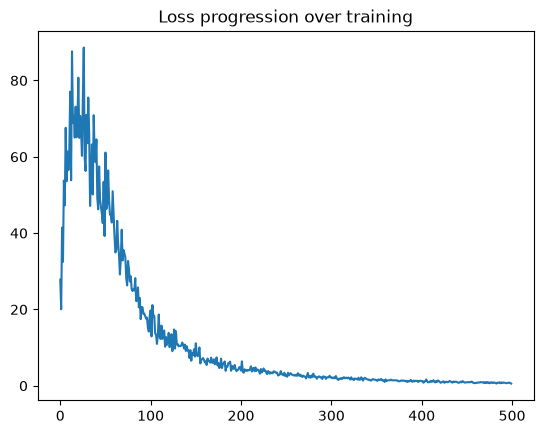

In [85]:

loss_hist, y0_hist = train(model=model, opt=opt, batch_size=128, n_iter=500, d=d, N=N, dt=dt, xi=S0)
print(f"Y0 = {model.y0.item():.4f}, exact u(0, xi) = {price:.4f}")

plt.plot(loss_hist)
plt.title("Loss progression over training")
plt.show()

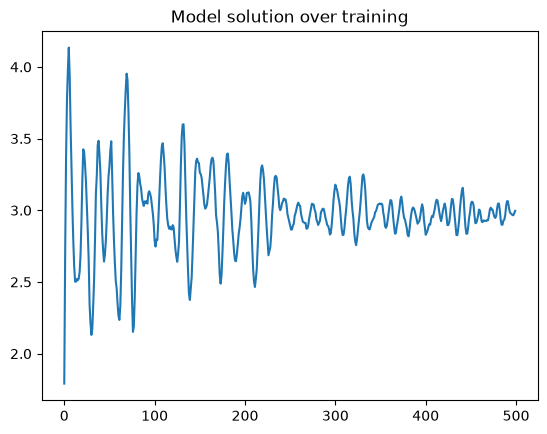

In [86]:
plt.plot(y0_hist)
plt.title("Model solution over training")
plt.show()